COMPROBACION 1: K=3, m=2, s=3, N=101, T=60000 contra la Fase 7


  np.array_equal = True  (forma (100, 101))  [52.3 s]



COMPROBACION 2: juego binario


N= 51 m= 1  z=   0.0392  sigma2/N=    1.1223  [4.9 s]


N= 51 m= 2  z=   0.0784  sigma2/N=    0.7029  [5.2 s]


N= 51 m= 3  z=   0.1569  sigma2/N=    0.3985  [5.0 s]


... (28 outputs left out)

  N=101: minimo 0.0731 en z=0.6337 (m=6)   con m=10: 0.2203 en z=10.1386


  N=201: minimo 0.0856 en z=0.6368 (m=7)   con m=10: 0.2028 en z=5.0945



Grafica de sigma^2/N contra z:


  Guardado: graficas\Fase8_sigma2_contra_z_K2_s2_T6000_N51-101-201_m1-a-10.png


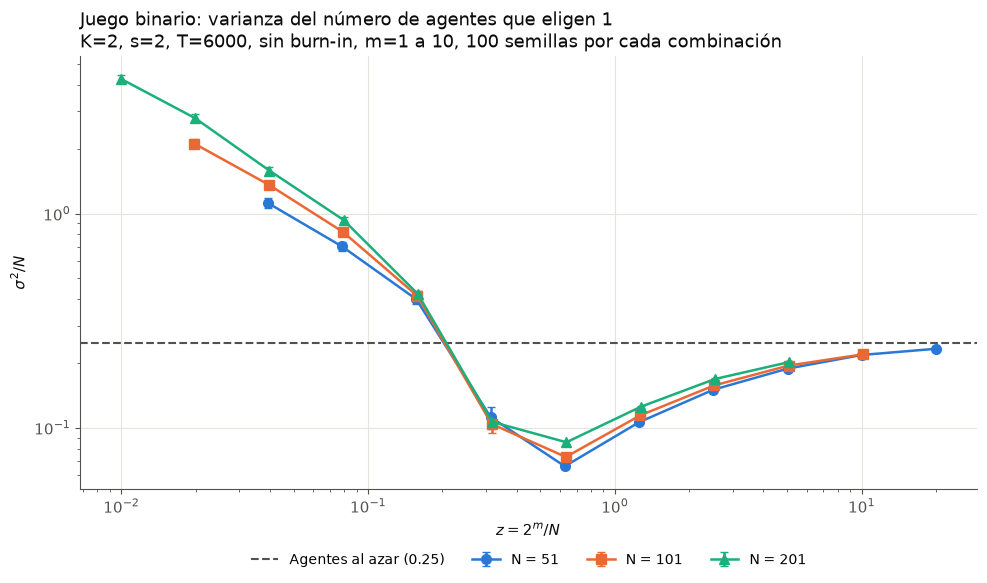


Listo. Tiempo total: 3.5 min


In [1]:
"""
FASE 8 - Version binaria del minority game: validacion contra la literatura
===========================================================================
Tesis: Complejidad e informacion en un minority game con opcion de abstencion

El numero de opciones K es un parametro:
  K = 3 -> alfabeto {0, 1, 2}, 3^m historias, N no multiplo de 3
  K = 2 -> alfabeto {0, 1},    2^m historias, N impar
Todo lo demas es igual en los dos juegos: regla de la minoria, puntaje,
desempate entre estrategias, semillas y joblib.

Que hace este codigo:
  COMPROBACION 1 (que no se rompio nada). Con K = 3, m = 2, s = 3, N = 101 y
     T = 60000, compara el CSV de M(d) de todas las cadenas contra el de la
     Fase 7 con np.array_equal. Si no son identicos, el notebook se detiene.
  COMPROBACION 2 (validacion del juego binario). Con K = 2, s = 2, T = 6000,
     100 cadenas, N = 51, 101 y 201, y m = 1 a 10, calcula sigma^2/N, donde
     sigma^2 es la varianza en el tiempo del numero de agentes que eligen 1
     en cada cadena, y la promedia sobre las cadenas. Grafica sigma^2/N contra
     z = 2^m/N en escala log-log, con la linea de agentes al azar en 0.25.

z = K^m / N es el mismo parametro de control que gamma en los otros notebooks.

Las funciones regla_ganador, informacion_mutua, complejidad_fisica, resumir,
guardar_Md_todas y terminar_figura son las de la Fase 7, sin cambios de codigo.
simular_con_puntaje, correr_cadena y correr_N son las de la Fase 7, y lo unico
que se les agrego es devolver los conteos de cada opcion en cada turno.
"""

import os
import time

import numpy as np
import matplotlib.pyplot as plt

try:
    from scipy.stats import t as t_student
except ImportError:
    t_student = None
T_95 = 1.984  # t de Student, 95%, 99 g.l. (por si no hay scipy)

try:
    from joblib import Parallel, delayed
    HAY_JOBLIB = True
except ImportError:
    HAY_JOBLIB = False


# =====================================================================
# OPCIONES
# =====================================================================
# Las graficas SIEMPRE se muestran en el notebook.
# True  = ademas se guardan como PNG en CARPETA_GRAFICAS
# False = solo se muestran, no se guarda ningun PNG
DESCARGAR_GRAFICAS = True

# True  = se guarda un CSV con sigma^2/N de la comprobacion 2
# False = no se guarda ese CSV (los CSV de la comprobacion 1 siempre se escriben,
#         porque la comparacion se hace justamente entre esos archivos)
GUARDAR_CSV        = False

# True  = se guardan los conteos de cada opcion en cada turno (comprobacion 2)
# False = no se guardan
GUARDAR_CONTEOS    = True

# Para correr solo una de las dos comprobaciones
HACER_COMPROBACION_1 = True
HACER_COMPROBACION_2 = True

CARPETA_CSV            = "csv"
CARPETA_GRAFICAS       = "graficas"
CARPETA_CONTEOS        = "conteos"
CARPETA_COMPROBACIONES = "comprobaciones"

#   -1 -> usa TODOS los nucleos
#   -2 -> usa todos menos uno (la computadora queda mas libre mientras corre)
#    1 -> un solo nucleo
N_NUCLEOS = -1


# =====================================================================
# PARAMETROS
# =====================================================================
SEMILLA_MAESTRA = 1907443528   # genera las 100 semillas de forma reproducible
N_CADENAS = 100                # numero de cadenas (semillas distintas)

D_MAX   = 100    # M(d) se calcula para d = 1, ..., D_MAX
L_MAX   = 6      # la complejidad se calcula para l = 1, ..., L_MAX
NIVEL   = 0.95   # nivel de confianza del intervalo

# --- Comprobacion 1: juego de tres opciones, igual que en la Fase 7 ---
K_C1 = 3
M_C1 = 2
S_C1 = 3
N_C1 = 101
T_C1 = 60000
ARCHIVO_REFERENCIA_C1 = os.path.join(
    CARPETA_COMPROBACIONES,
    f"Fase7_referencia_Md_con_puntaje_N{N_C1}_m{M_C1}_s{S_C1}_T{T_C1}_todas_las_cadenas.csv")

# --- Comprobacion 2: juego binario ---
K_BIN = 2
S_BIN = 2
T_BIN = 6000
LISTA_N_BIN = [51, 101, 201]
LISTA_M_BIN = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
VALOR_AZAR = 0.25   # sigma^2/N de agentes que eligen al azar

ETIQUETA = "con_puntaje"


# =====================================================================
# VALIDAR LOS PARAMETROS
# =====================================================================
def validar_parametros(N, K):
    """Con K = 2, N impar evita el empate entre las dos opciones.
    Con K = 3, N no multiplo de 3 evita el empate entre las tres."""
    if K == 2 and N % 2 == 0:
        raise ValueError(f"Con K = 2, N debe ser impar (N = {N})")
    if K == 3 and N % 3 == 0:
        raise ValueError(f"Con K = 3, N no debe ser multiplo de 3 (N = {N})")


# =====================================================================
# REGLA DE GANADOR  (igual que en la Fase 7)
# =====================================================================
def regla_ganador(conteos, rng):
    """Gana el argmin sobre las K acciones, con desempate aleatorio."""
    empatados = np.flatnonzero(conteos == conteos.min())
    return int(rng.choice(empatados))


# =====================================================================
# s ESTRATEGIAS POR AGENTE, CON PUNTAJE  (Fase 7 + conteos por turno)
# =====================================================================
def simular_con_puntaje(N, m, s, K, T, semilla):
    """Reglas del codigo base, sin burn-in. Cada agente usa la estrategia
    con mas puntos y, al final del ciclo, todas las estrategias que
    habrian acertado al ganador reciben un punto.

    Devuelve la serie de ganadores, cuantas veces acerto cada agente y
    cuantos agentes eligieron cada opcion en cada turno.
    """
    rng = np.random.default_rng(semilla)
    N_HIST = K ** m

    # estrategias[i, j, h] = accion que la estrategia j del agente i
    #                        recomienda ante la historia con indice h
    estrategias = rng.integers(0, K, size=(N, s, N_HIST))

    # puntajes[i, j] = puntos virtuales (casos de exito) de esa estrategia
    puntajes = np.zeros((N, s))

    # memoria: los m datos que el mercado tiene "al nacer"
    historia = rng.integers(0, K, size=m)

    pesos = K ** np.arange(m - 1, -1, -1)   # convierte historia -> indice
    indices = np.arange(N)

    serie_ganadores = np.zeros(T, dtype=int)
    exitos_agente = np.zeros(N, dtype=int)
    conteos_por_turno = np.zeros((T, K), dtype=np.int32)

    for t in range(T):

        # 1. que situacion estan viendo los agentes
        idx = int(historia @ pesos)

        # 2. cada agente toma su estrategia con mas puntos.
        #    El ruido < 1 rompe empates al azar sin alterar el orden
        #    entre puntajes enteros distintos.
        mejor = np.argmax(puntajes + rng.random((N, s)) * 0.5, axis=1)

        # 3. consulta esa estrategia en la historia actual y actua
        acciones = estrategias[indices, mejor, idx]

        # 4. se cuenta cuantos eligieron cada opcion
        conteos = np.bincount(acciones, minlength=K)

        # 5. gana la minoria
        ganador = regla_ganador(conteos, rng)

        # 6. se premian TODAS las estrategias que hubieran acertado,
        #    se hayan jugado o no (regla del codigo base / PRE 62).
        puntajes += (estrategias[:, :, idx] == ganador)

        # 7. registrar desde el primer ciclo
        serie_ganadores[t] = ganador
        conteos_por_turno[t] = conteos
        exitos_agente += (acciones == ganador)

        # 8. la memoria se desplaza: entra el ganador, sale el mas viejo
        historia = np.roll(historia, -1)
        historia[-1] = ganador

    return serie_ganadores, exitos_agente, conteos_por_turno


# =====================================================================
# FUNCION DE INFORMACION MUTUA  -  Ec. (6) del PRE 62  (igual que en la Fase 7)
# =====================================================================
def informacion_mutua(serie, d, K):
    """M(d) = sum_{a,b} P_ab(d) * log2[ P_ab(d) / (P_a * P_b) ]

    P_ab(d): probabilidad de encontrar el simbolo a y, d lugares despues,
             el simbolo b. Se estima contando todos los pares
             (serie[i], serie[i+d]) de la cadena.
    P_a:     densidad del simbolo a en la cadena completa (como dice
             Mansilla: "the density of the symbol alpha").

    La suma corre sobre los K*K pares (a, b). Los pares que nunca
    aparecen (P_ab = 0) no aportan, porque 0 * log(0) = 0.
    """
    x = serie[:-d]          # simbolo alpha
    y = serie[d:]           # simbolo beta, d lugares despues
    n_pares = len(x)

    # probabilidades conjuntas P_ab(d): matriz K x K
    conjunta = np.bincount(x * K + y, minlength=K * K).reshape(K, K) / n_pares

    # densidades P_a de cada simbolo en toda la cadena
    densidad = np.bincount(serie, minlength=K) / len(serie)
    producto = np.outer(densidad, densidad)      # P_a * P_b

    M_d = 0.0
    for a in range(K):
        for b in range(K):
            if conjunta[a, b] > 0:
                M_d += conjunta[a, b] * np.log2(conjunta[a, b] / producto[a, b])
    return M_d


# =====================================================================
# COMPLEJIDAD FISICA  (igual que en la Fase 7)
# =====================================================================
def complejidad_fisica(serie, l, K):
    """Devuelve C_K(l) y c_K(l) de una cadena de ganadores.

    Una ventana de longitud l recorre la cadena de uno en uno. Cada ventana
    se convierte en un numero (en base K) para contar cuantas veces aparece
    cada subcadena eta. Con esas frecuencias relativas p(eta):

        H(l)   = -sum p(eta) log2 p(eta)
        C_K(l) = l*log2(K) - H(l)
        c_K(l) = C_K(l) / (l*log2(K))
    """
    ventanas = np.lib.stride_tricks.sliding_window_view(serie, l)
    pesos = K ** np.arange(l - 1, -1, -1)
    codigos = ventanas @ pesos
    conteos = np.bincount(codigos, minlength=K ** l)

    p = conteos[conteos > 0] / len(codigos)
    H = -np.sum(p * np.log2(p))

    maximo = l * np.log2(K)
    C = maximo - H
    return C, C / maximo


# =====================================================================
# UNA CADENA COMPLETA  (Fase 7 + conteos por turno)
# =====================================================================
def correr_cadena(N, m, s, K, T, semilla, d_max, l_max):
    serie, exitos, conteos = simular_con_puntaje(N, m, s, K, T, int(semilla))
    Md = np.array([informacion_mutua(serie, d, K)
                   for d in range(1, d_max + 1)])
    complejidad = np.array([complejidad_fisica(serie, l, K)
                            for l in range(1, l_max + 1)])
    return {
        "Md": Md,
        "C": complejidad[:, 0],
        "c": complejidad[:, 1],
        "frec": np.bincount(serie, minlength=K) / T,
        "tasa_exito": exitos.sum() / (N * T),
        "conteos": conteos,
    }


def correr_N(N, m, s, K, T, semillas, d_max, l_max, n_nucleos):
    """Corre todas las cadenas de un N. El resultado no depende del numero
    de nucleos: cada cadena usa solo su propia semilla y joblib devuelve
    las cadenas en el orden en que se pidieron."""
    validar_parametros(N, K)
    if HAY_JOBLIB and n_nucleos != 1:
        bloque = Parallel(n_jobs=n_nucleos)(
            delayed(correr_cadena)(N, m, s, K, T, int(sem), d_max, l_max)
            for sem in semillas)
    else:
        bloque = [correr_cadena(N, m, s, K, T, int(sem), d_max, l_max)
                  for sem in semillas]
    return {
        "Md": np.array([b["Md"] for b in bloque]),
        "C": np.array([b["C"] for b in bloque]),
        "c": np.array([b["c"] for b in bloque]),
        "frec": np.array([b["frec"] for b in bloque]),
        "tasa_exito": np.array([b["tasa_exito"] for b in bloque]),
        "conteos": np.array([b["conteos"] for b in bloque]),
    }


def resumir(tabla, t_crit):
    """Promedio sobre las cadenas (filas), con su intervalo de confianza."""
    media = tabla.mean(axis=0)
    desv = tabla.std(axis=0, ddof=1)
    error_est = desv / np.sqrt(tabla.shape[0])
    return {"media": media, "desv": desv, "error_est": error_est,
            "ic_inf": media - t_crit * error_est,
            "ic_sup": media + t_crit * error_est}


# =====================================================================
# GUARDAR LOS RESULTADOS
# =====================================================================
def guardar_Md_todas(ruta, tabla, semillas, encabezado):
    """Mismo formato que los CSV de las fases 2 y 3."""
    distancias = np.arange(1, tabla.shape[1] + 1)
    np.savetxt(ruta, np.column_stack([np.asarray(semillas).astype(np.int64), tabla]),
               fmt=["%d"] + ["%.8e"] * tabla.shape[1], delimiter=",",
               header=(encabezado + "\nsemilla,"
                       + ",".join(f"d{d}" for d in distancias)),
               comments="# ")


def guardar_conteos(N, m, s, K, T, conteos, semillas):
    """Guarda una matriz con forma (cadenas, T, K). conteos[c, t, a] es el
    numero de agentes que eligieron la opcion a en el turno t de la cadena c."""
    ruta = os.path.join(CARPETA_CONTEOS,
                        f"Fase8_conteos_K{K}_N{N}_m{m}_s{s}_T{T}"
                        f"_cadenas{len(semillas)}.npz")
    np.savez_compressed(ruta, conteos=conteos, semillas=semillas)


# =====================================================================
# GRAFICA
# =====================================================================
COLORES_N = dict(zip(LISTA_N_BIN, ["#2a78d6", "#eb6834", "#1baf7a"]))  # uno por N
MARCAS_N  = dict(zip(LISTA_N_BIN, ["o", "s", "^"]))
GRIS = "#52514e"
TINTA = "#0b0b0b"


def terminar_figura(fig, archivo):
    if DESCARGAR_GRAFICAS:
        ruta = os.path.join(CARPETA_GRAFICAS, archivo)
        fig.savefig(ruta, dpi=200)
        print(f"  Guardado: {ruta}", flush=True)
    plt.show()
    plt.close(fig)


def graficar_sigma2(resultados):
    fig, ax = plt.subplots(figsize=(10, 6))
    for N in LISTA_N_BIN:
        z = np.array([K_BIN ** m / N for m in LISTA_M_BIN])
        r = resultados[N]
        inf = np.maximum(r["ic_inf"], r["media"] * 0.01)
        ax.errorbar(z, r["media"], yerr=[r["media"] - inf, r["ic_sup"] - r["media"]],
                    color=COLORES_N[N], marker=MARCAS_N[N], ms=7, lw=1.8, capsize=3,
                    label=f"N = {N}")
    ax.axhline(VALOR_AZAR, color=GRIS, lw=1.5, ls="--",
               label=f"Agentes al azar ({VALOR_AZAR})")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("$z = 2^m / N$")
    ax.set_ylabel(r"$\sigma^2 / N$")
    ax.set_title("Juego binario: varianza del número de agentes que eligen 1\n"
                 f"K={K_BIN}, s={S_BIN}, T={T_BIN}, sin burn-in, m={LISTA_M_BIN[0]} a "
                 f"{LISTA_M_BIN[-1]}, {N_CADENAS} semillas por cada combinación",
                 loc="left", color=TINTA)
    ax.grid(which="major", color="#e5e4df", lw=0.8)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12),
              ncol=4, fontsize=10)
    fig.tight_layout()
    nombres_N = "-".join(str(N) for N in LISTA_N_BIN)
    terminar_figura(fig, f"Fase8_sigma2_contra_z_K{K_BIN}_s{S_BIN}_T{T_BIN}"
                         f"_N{nombres_N}_m{LISTA_M_BIN[0]}-a-{LISTA_M_BIN[-1]}.png")


# =====================================================================
# COMPROBACIONES
# =====================================================================
def comprobacion_1(semillas):
    print("COMPROBACION 1: K=3, m=2, s=3, N=101, T=60000 contra la Fase 7", flush=True)
    t0 = time.time()
    datos = correr_N(N_C1, M_C1, S_C1, K_C1, T_C1, semillas, D_MAX, L_MAX, N_NUCLEOS)
    ruta = os.path.join(CARPETA_COMPROBACIONES,
                        f"Fase8_comprobacion1_Md_{ETIQUETA}_K{K_C1}_N{N_C1}_m{M_C1}"
                        f"_s{S_C1}_T{T_C1}_todas_las_cadenas.csv")
    guardar_Md_todas(ruta, datos["Md"], semillas,
                     f"FASE 8. Comprobacion 1. M(d) de cada cadena\n"
                     f"N={N_C1} m={M_C1} s={S_C1} K={K_C1} T={T_C1} burn_in=0 {ETIQUETA}")
    referencia = np.loadtxt(ARCHIVO_REFERENCIA_C1, delimiter=",", comments="#")
    nueva = np.loadtxt(ruta, delimiter=",", comments="#")
    iguales = np.array_equal(referencia, nueva)
    print(f"  np.array_equal = {iguales}  (forma {nueva.shape})  "
          f"[{time.time() - t0:.1f} s]", flush=True)
    if not iguales:
        raise RuntimeError("COMPROBACION 1 FALLIDA: el CSV de M(d) no es identico "
                           "al de la Fase 7. El notebook se detiene aqui.")


def comprobacion_2(semillas, t_crit):
    print("\nCOMPROBACION 2: juego binario", flush=True)
    if GUARDAR_CONTEOS:
        os.makedirs(CARPETA_CONTEOS, exist_ok=True)
    resultados = {}
    filas = []
    for N in LISTA_N_BIN:
        tabla = np.zeros((N_CADENAS, len(LISTA_M_BIN)))
        for j, m in enumerate(LISTA_M_BIN):
            t0 = time.time()
            datos = correr_N(N, m, S_BIN, K_BIN, T_BIN, semillas, D_MAX, L_MAX, N_NUCLEOS)

            # varianza en el tiempo, cadena por cadena, de los que eligen 1
            tabla[:, j] = datos["conteos"][:, :, 1].var(axis=1) / N

            if GUARDAR_CONTEOS:
                guardar_conteos(N, m, S_BIN, K_BIN, T_BIN, datos["conteos"], semillas)
            z = K_BIN ** m / N
            print(f"N={N:3d} m={m:2d}  z={z:9.4f}  sigma2/N={tabla[:, j].mean():10.4f}  "
                  f"[{time.time() - t0:.1f} s]", flush=True)
        resultados[N] = resumir(tabla, t_crit)
        r = resultados[N]
        for j, m in enumerate(LISTA_M_BIN):
            filas.append([N, m, K_BIN ** m / N, r["media"][j], r["desv"][j],
                          r["error_est"][j], r["ic_inf"][j], r["ic_sup"][j]])

    print("\nMinimo de sigma2/N y valor con la z mas grande:")
    for N in LISTA_N_BIN:
        media = resultados[N]["media"]
        j = int(np.argmin(media))
        print(f"  N={N:3d}: minimo {media[j]:.4f} en z={K_BIN ** LISTA_M_BIN[j] / N:.4f} "
              f"(m={LISTA_M_BIN[j]})   con m={LISTA_M_BIN[-1]}: {media[-1]:.4f} "
              f"en z={K_BIN ** LISTA_M_BIN[-1] / N:.4f}", flush=True)

    if GUARDAR_CSV:
        os.makedirs(CARPETA_CSV, exist_ok=True)
        ruta = os.path.join(CARPETA_CSV,
                            f"Fase8_sigma2_K{K_BIN}_s{S_BIN}_T{T_BIN}_resumen.csv")
        np.savetxt(ruta, np.array(filas),
                   fmt=["%d", "%d", "%.6f"] + ["%.8e"] * 5, delimiter=",", comments="# ",
                   header=(f"FASE 8. sigma^2/N, K={K_BIN} s={S_BIN} T={T_BIN} "
                           f"cadenas={N_CADENAS} semilla_maestra={SEMILLA_MAESTRA}\n"
                           "N,m,gamma,media,desv_estandar,error_estandar,"
                           "ic_inferior,ic_superior"))
        print(f"Guardado: {ruta}")
    return resultados


# =====================================================================
# PROGRAMA PRINCIPAL
# =====================================================================
if __name__ == "__main__":
    inicio = time.time()

    # --- las 100 semillas (las mismas para todas las combinaciones) ---
    semillas = np.random.SeedSequence(SEMILLA_MAESTRA).generate_state(N_CADENAS)
    t_crit = (t_student.ppf(0.5 + NIVEL / 2, N_CADENAS - 1)
              if t_student is not None else T_95)

    if DESCARGAR_GRAFICAS:
        os.makedirs(CARPETA_GRAFICAS, exist_ok=True)
    os.makedirs(CARPETA_COMPROBACIONES, exist_ok=True)
    if not HAY_JOBLIB:
        print("AVISO: joblib no esta instalado -> se usa un solo nucleo "
              "(pip install joblib)")

    plt.rcParams.update({
        "font.size": 11,
        "axes.edgecolor": GRIS,
        "axes.labelcolor": TINTA,
        "xtick.color": GRIS,
        "ytick.color": GRIS,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })

    if HACER_COMPROBACION_1:
        comprobacion_1(semillas)

    if HACER_COMPROBACION_2:
        resultados = comprobacion_2(semillas, t_crit)
        print("\nGrafica de sigma^2/N contra z:")
        graficar_sigma2(resultados)

    print(f"\nListo. Tiempo total: {(time.time() - inicio) / 60:.1f} min")
